In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


In [2]:

file_path = Path.cwd() / "output" / "PerfectPetClub_Churn.parquet"

df = pd.read_parquet(file_path)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (221, 26)


,id_customer,subscription_id,id_subscription,start_date,end_date,auto_renew,subscription_type_id,subscription_type,delivery_service,churn,...,first_login,last_login,reported_income,nps_recommend,satisfaction_score,online_comparison_freq,customer_id_sales,total_orders,first_order,last_order
0,1,1,1,2026-01-01,2026-01-31,0,3,SuperSaver,Economy72,1.0,...,2026-01-01 17:28:25.008,2026-01-11 15:41:35.247,26k-30k,8,6,5,1,20,2026-01-01,2026-01-10 20:43:36.234
1,2,2,2,2026-01-01,2026-11-27,1,3,SuperSaver,Economy72,0.0,...,2026-01-01 16:48:25.008,2026-11-09 21:35:20.498,34k-38k,5,8,9,2,253,2026-01-01,2026-11-09 21:35:20.498
2,3,3,3,2026-01-01,2026-11-27,1,1,Premium,SignedFor24,0.0,...,2026-01-01 17:40:25.009,2026-11-09 20:43:20.496,26k-30k,9,5,5,3,304,2026-01-01,2026-11-07 21:31:22.450
3,4,4,4,2026-01-01,2026-11-27,1,1,Premium,SignedFor24,0.0,...,2026-01-01 14:35:05.006,2026-11-09 21:56:40.499,198k-200k+,9,3,5,4,1055,2026-01-01,2026-11-09 21:56:40.499
4,5,5,5,2026-01-01,2026-05-01,0,3,SuperSaver,Economy72,1.0,...,2026-01-01 17:51:05.010,2026-04-13 20:45:25.463,42k-46k,0,8,10,5,44,2026-01-01,2026-04-12 19:52:46.436


In [3]:

print("Total customers:", len(df))
print("Churned customers:", int(df["churn"].sum()))
print("Churn rate:", round(df["churn"].mean() * 100, 2), "%")

display(df.dtypes)


Total customers: 221
Churned customers: 86
Churn rate: 38.91 %


id_customer                        int64
subscription_id                    int64
id_subscription                    int64
start_date                datetime64[ns]
end_date                  datetime64[ns]
auto_renew                         int64
subscription_type_id               int64
subscription_type                 object
delivery_service                  object
churn                            float64
customer_id                      float64
total_interactions               float64
complaint_count                  float64
query_count                      float64
total_logins                       int64
unique_sessions                    int64
first_login               datetime64[ns]
last_login                datetime64[ns]
reported_income                   object
nps_recommend                      int64
satisfaction_score                 int64
online_comparison_freq             int64
customer_id_sales                  int64
total_orders                       int64
first_order     

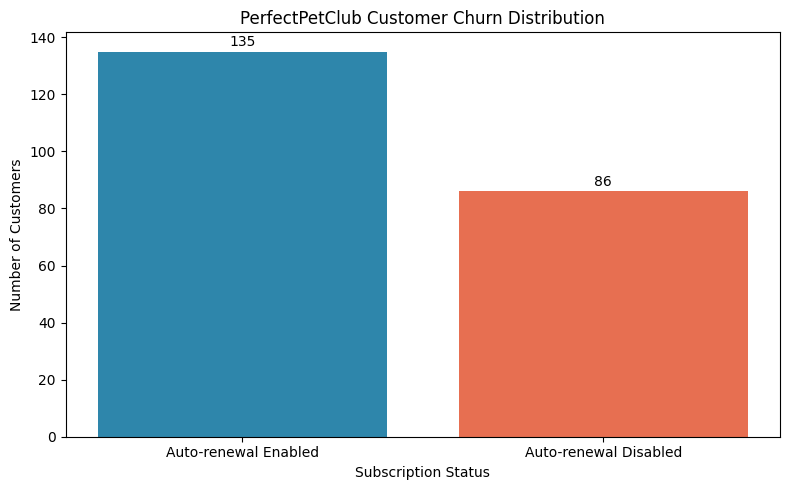

In [4]:

churn_counts = df["churn"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

plt.bar(
    ["Auto-renewal Enabled", "Auto-renewal Disabled"],
    churn_counts.values,
    color=["#2E86AB", "#E76F51"]
)

plt.title("PerfectPetClub Customer Churn Distribution")
plt.ylabel("Number of Customers")
plt.xlabel("Subscription Status")

for index, value in enumerate(churn_counts.values):
    plt.text(index, value + 2, str(value), ha="center")

plt.tight_layout()
plt.show()


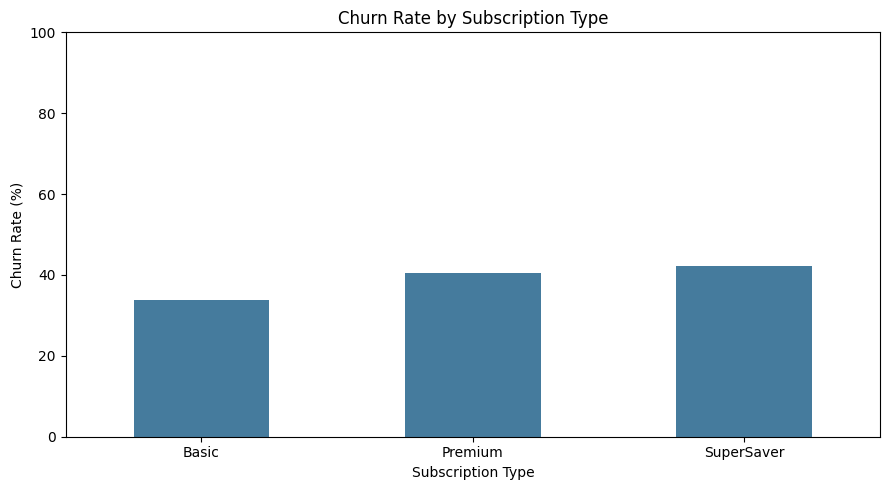

In [5]:

subscription_churn = (
    df.groupby("subscription_type")["churn"]
    .mean()
    .mul(100)
    .sort_values()
)

plt.figure(figsize=(9, 5))

subscription_churn.plot(
    kind="bar",
    color="#457B9D"
)

plt.title("Churn Rate by Subscription Type")
plt.xlabel("Subscription Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)

plt.tight_layout()
plt.show()


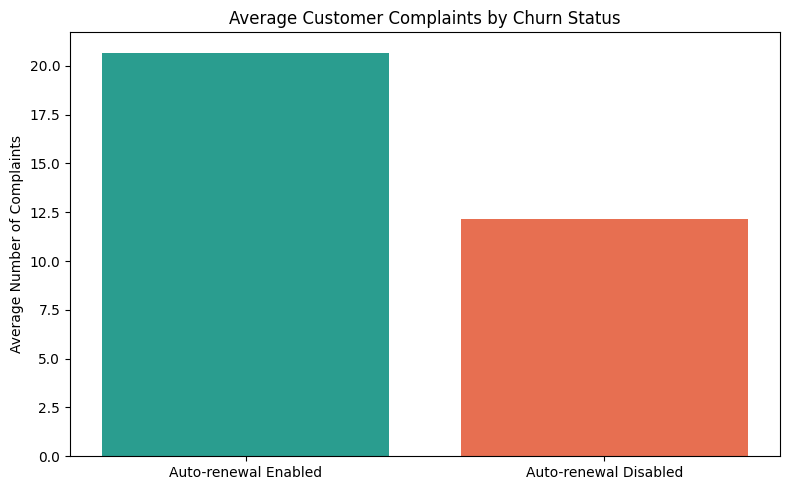

In [6]:

complaint_churn = df.groupby("churn")["complaint_count"].mean()

plt.figure(figsize=(8, 5))

plt.bar(
    ["Auto-renewal Enabled", "Auto-renewal Disabled"],
    complaint_churn.values,
    color=["#2A9D8F", "#E76F51"]
)

plt.title("Average Customer Complaints by Churn Status")
plt.ylabel("Average Number of Complaints")

plt.tight_layout()
plt.show()


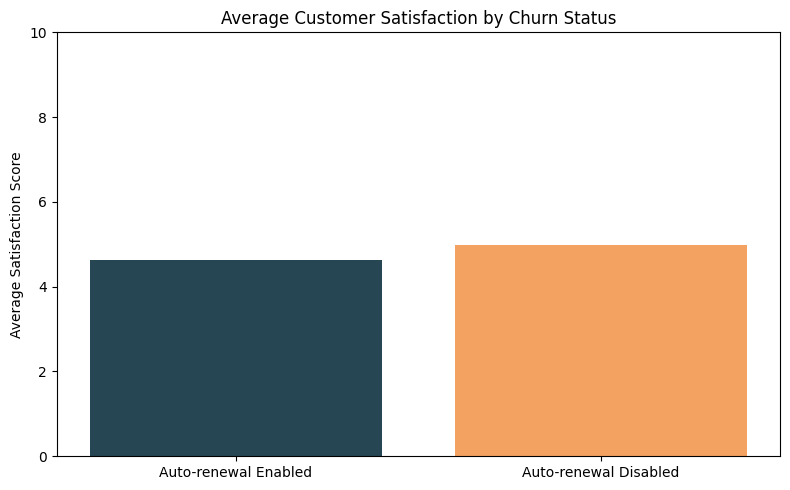

In [7]:

satisfaction_churn = df.groupby("churn")["satisfaction_score"].mean()

plt.figure(figsize=(8, 5))

plt.bar(
    ["Auto-renewal Enabled", "Auto-renewal Disabled"],
    satisfaction_churn.values,
    color=["#264653", "#F4A261"]
)

plt.title("Average Customer Satisfaction by Churn Status")
plt.ylabel("Average Satisfaction Score")
plt.ylim(0, 10)

plt.tight_layout()
plt.show()


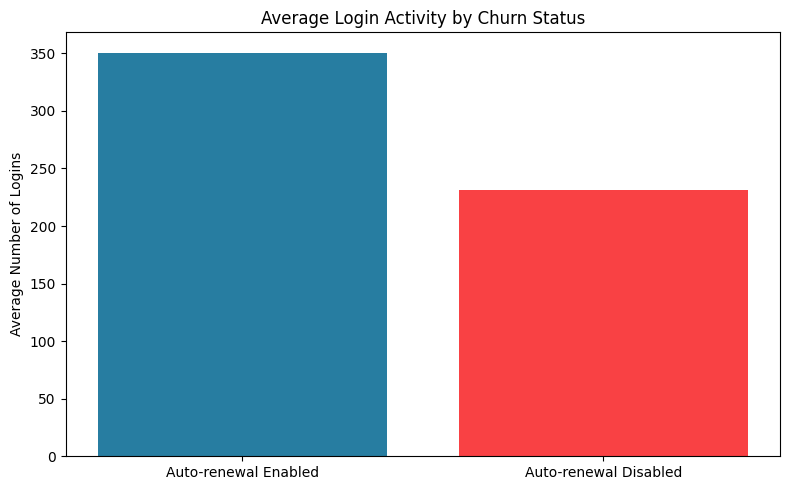

In [8]:

login_churn = df.groupby("churn")["total_logins"].mean()

plt.figure(figsize=(8, 5))

plt.bar(
    ["Auto-renewal Enabled", "Auto-renewal Disabled"],
    login_churn.values,
    color=["#277DA1", "#F94144"]
)

plt.title("Average Login Activity by Churn Status")
plt.ylabel("Average Number of Logins")

plt.tight_layout()
plt.show()


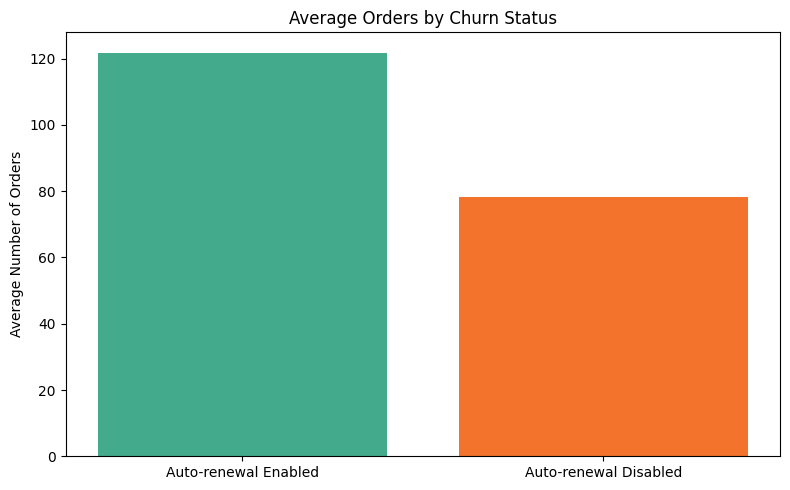

In [9]:

order_churn = df.groupby("churn")["total_orders"].mean()

plt.figure(figsize=(8, 5))

plt.bar(
    ["Auto-renewal Enabled", "Auto-renewal Disabled"],
    order_churn.values,
    color=["#43AA8B", "#F3722C"]
)

plt.title("Average Orders by Churn Status")
plt.ylabel("Average Number of Orders")

plt.tight_layout()
plt.show()
